# Part 1: Training and Model Evaluation

## Setup and Importing of Dataset

In [1]:
import platform, os, time, re, json, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import lightgbm as lgb
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import precision_recall_curve, auc, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


np.random.seed(42)
torch.manual_seed(42)

df = pd.read_csv('Dataset.csv')
print("=== RUNTIME ENVIRONMENT ===")
print("Architecture :", platform.machine(), " (s390x = IBM Z / LinuxONE)")


=== RUNTIME ENVIRONMENT ===
Architecture : s390x  (s390x = IBM Z / LinuxONE)


## Simple EDA

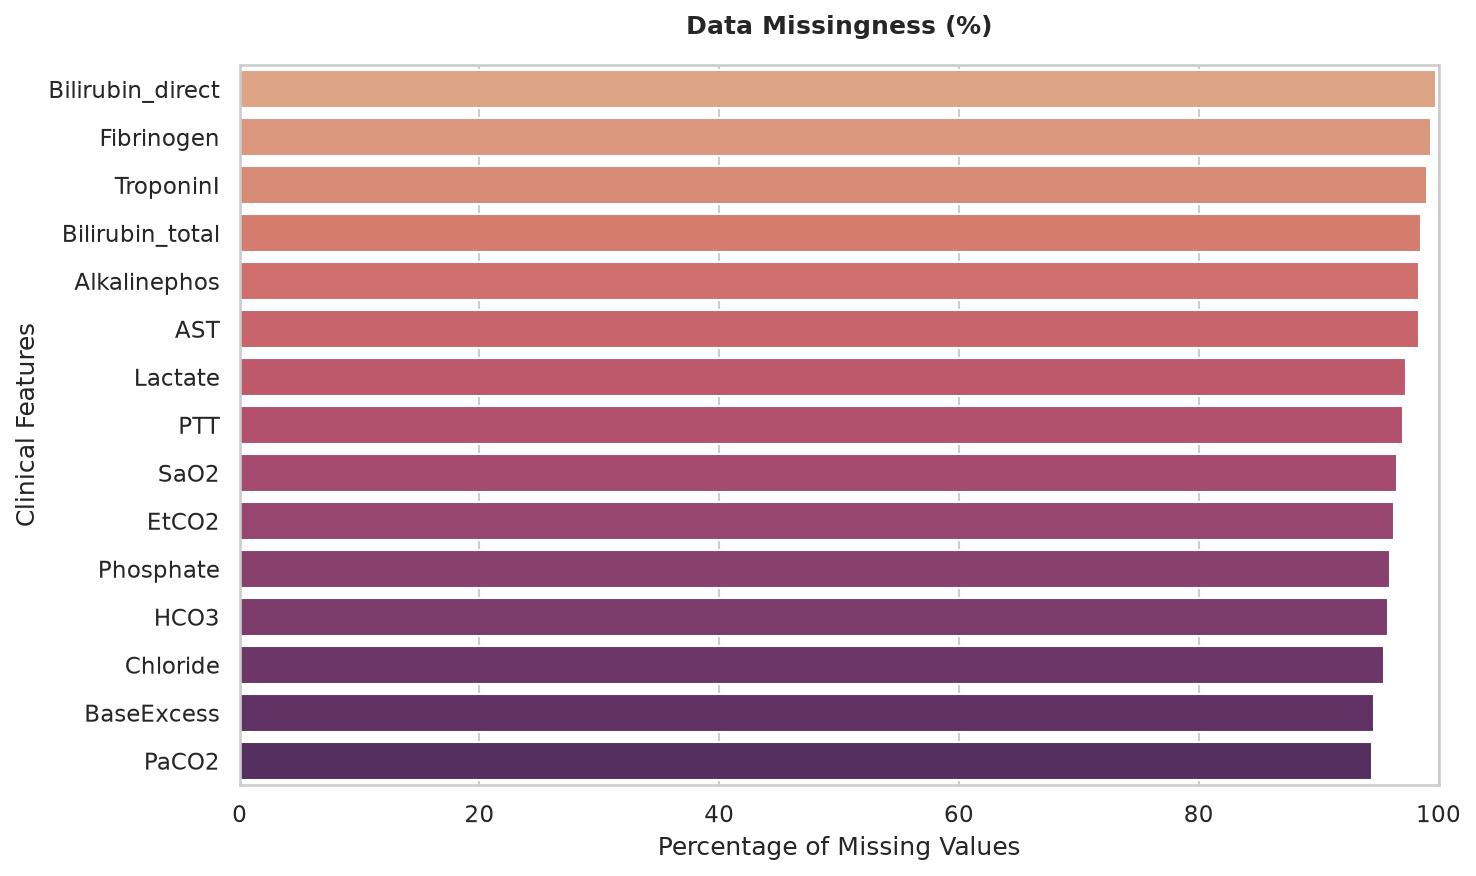

In [2]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12, 'figure.dpi': 150})

plt.figure(figsize=(10, 6))
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False).head(15)

if not missing_pct.empty:
    sns.barplot(x=missing_pct.values, y=missing_pct.index, palette="flare")
    plt.title('Data Missingness (%)', fontweight='bold', pad=15)
    plt.xlabel('Percentage of Missing Values')
    plt.ylabel('Clinical Features')
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.savefig('raw_eda_1_missingness.png', bbox_inches='tight')
    plt.show()
else:
    print("No missing data found in the dataset.")

As seen above, we have multiple columns with >95% in missing data. In standard machine learning practices, this level of missingness would force us to drop these columns entirely or drop the patients. However, this sparsity is not 'bad data' since they are clinical data. While some metrics such as heart rate is able to be monitored continuously, other metrics such as Lactate and Troponin are only done once every few hours. 

Understanding this reality changed our approach to handling missing data. Instead of relying on basic imputation such as mean, mode and median that would destroy the variance, we utilized forward-filling to carry the last known lab value forward until a new draw occurred. Furthermore, this extreme missingness is the exact reason we deployed a PyTorch Denoising Autoencoder to reconstruct patient states. 

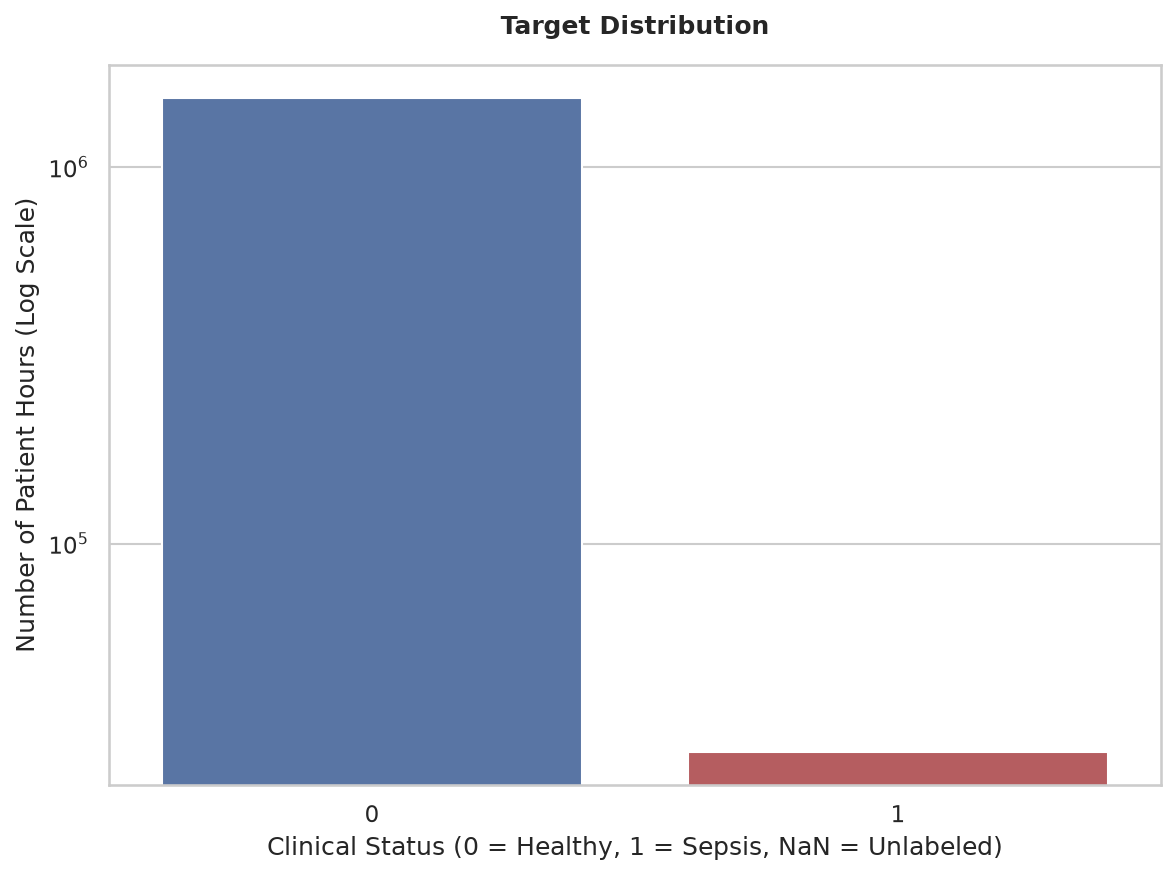

In [3]:
plt.figure(figsize=(8, 6))
# Include dropna=False to see if the target variable itself has missing rows
sns.countplot(data=df, x='SepsisLabel', palette=['#4C72B0', '#C44E52'])
plt.title('Target Distribution', fontweight='bold', pad=15)
plt.xlabel('Clinical Status (0 = Healthy, 1 = Sepsis, NaN = Unlabeled)')
plt.ylabel('Number of Patient Hours (Log Scale)')
plt.yscale('log')
plt.tight_layout()
plt.savefig('raw_eda_2_imbalance.png', bbox_inches='tight')
plt.show()

As seen above, there is an extreme class imbalance in the dataset. Even with the y-axis on a logarithmic scale, the disparity between healthy patient hours and sepsis hours is visually staggering. Because the healthy class outnumbers the sepsis cases by such a massive margin, a naive model that simply guesses 'healthy' every time would still achieve over 98% accuracy. This visualization is exactly why we abandoned standard accuracy metrics, shifted to Precision-Recall AUC, and aggressively weighted our loss function to ensure the algorithm didn't just ignore the clinical 'needle in the haystack'.

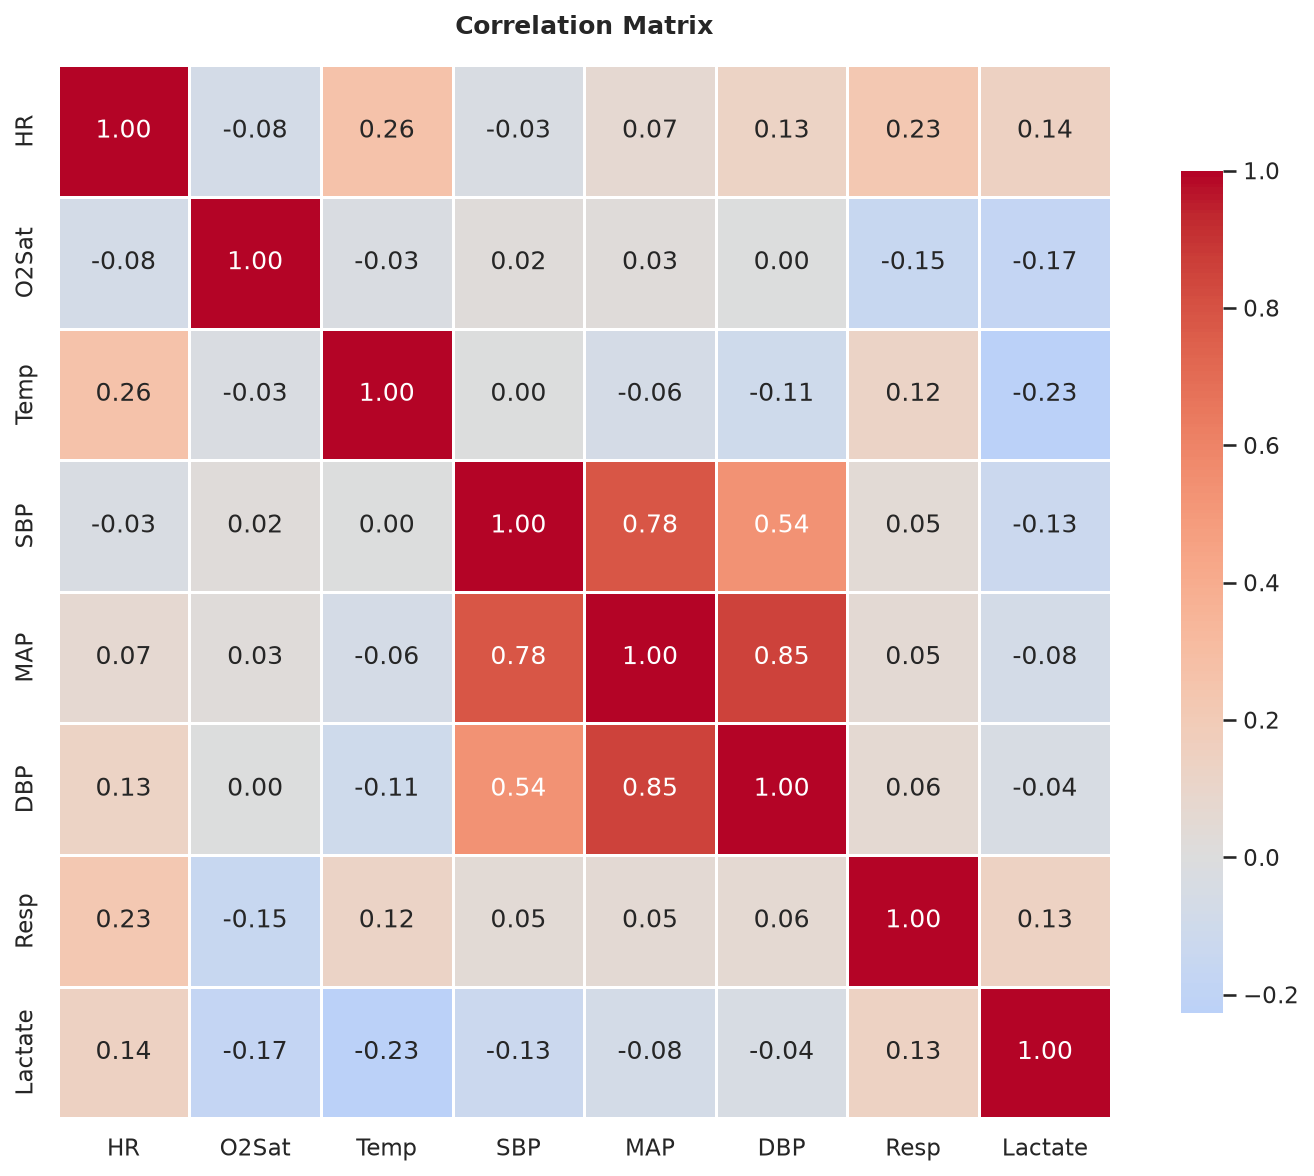

In [4]:
plt.figure(figsize=(10, 8))
target_features = ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'Lactate']
available_features = [col for col in target_features if col in df.columns]
corr_matrix_raw = df[available_features].corr()
sns.heatmap(corr_matrix_raw, annot=True, fmt=".2f", cmap="coolwarm", center=0, 
            square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title('Correlation Matrix', fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('raw_eda_3_heatmap.png', bbox_inches='tight')
plt.show()

From the correlation heatmap, we observed severe multicollinearity among the patient cardiovascular features. For example, Systolic Blood Pressure (SBP), Diastolic Blood Pressure (DBP), and Mean Arterial Pressure (MAP) are highly correlated, with MAP and DBP showing a correlation of 0.85, and MAP and SBP at 0.78. In an ICU setting, this is expected since these metrics are biologically and mathematically linked. However, for a machine learning model, feeding it highly correlated variables introduces redundant noise and destabilizes feature importance which drove us to engineer a PyTorch Denoising Autoencoder to computationally compress this collinear noise into clean, orthogonal patient embeddings.

## Data Cleaning and Feature Engineering

**Decisions made**

| Decision | Why |
|---|---|
| Drop rows with no `SepsisLabel`, drop `Unnamed` columns | A row without a label cannot be trained or scored; the index columns are export noise |
| Sort by `Patient_ID`, `Hour` | Forward-fill and the time-window analysis later assume chronological order |
| **Forward-fill within each patient** instead of mean/median imputation | Labs are drawn sparsely (>90% missing hour by hour). In practice a clinician treats the last result as current until a new one arrives, so carrying it forward mirrors reality. A global mean would erase the signal that a patient is abnormal |
| Keep remaining NaN | LightGBM routes missing values natively, and the autoencoder gets an explicit mask, so no fake values are invented |
| Separate `vital_cols` and `lab_cols` | Enables the Tier 2 (no-lab clinic) model later |


In [5]:
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')]) 
df = df.dropna(subset=['SepsisLabel'])
df = df.sort_values(['Patient_ID', 'Hour']).reset_index(drop=True)

feature_cols = [c for c in df.columns if c not in ('SepsisLabel', 'Patient_ID')]
lab_cols = feature_cols[feature_cols.index('BaseExcess'):feature_cols.index('Platelets') + 1]
vital_cols = ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'Age', 'Gender']

df[feature_cols] = df.groupby('Patient_ID')[feature_cols].ffill()

X_raw = df[feature_cols]
y = df['SepsisLabel'].astype(int)
groups = df['Patient_ID'].values

## Splitting of Data

Data is split by patient and now rows sinch each patient contributes dozens of correalted-hours. A row-level split lets the model see a patient's hour 30 in training and be tested on hour 31, so the score would measure memorisation of that patient. `GroupShuffleSplit` keeps all hours of a patient in one set.

In [6]:
# 80/20 Split by Patient.
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(outer.split(X_raw, y, groups))

# Validation Data
inner = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=7)
fit_pos, val_pos = next(inner.split(train_idx, groups=groups[train_idx]))
fit_idx, val_idx = train_idx[fit_pos], train_idx[val_pos]

for name, idx in [("Train", fit_idx), ("Validation", val_idx), ("Test", test_idx)]:
    print(f"{name:11s}: {len(np.unique(groups[idx])):6,} patients, {len(idx):9,} rows, sepsis rows {y.iloc[idx].mean()*100:.2f}%")

Train      : 27,427 patients, 1,055,653 rows, sepsis rows 1.85%
Validation :  4,841 patients,   185,560 rows, sepsis rows 1.69%
Test       :  8,068 patients,   310,997 rows, sepsis rows 1.69%


## Autoencoder

Compresses the 40 vital/lab/admin values of each patient-hour into 8 numbers (`embed_0..7`) that are added as extra features for Tier 1.

In [7]:
# Normalisation statistics come from training-side patients only (not test), so no test information leaks into the features.
mu = X_raw.iloc[train_idx].mean()
sd = X_raw.iloc[train_idx].std().replace(0, 1)
X_norm = (X_raw - mu) / sd
# Missing values become 0 and the mask records which entries were really measured
X_t = torch.tensor(X_norm.fillna(0).values, dtype=torch.float32)
M_t = torch.tensor(X_norm.notna().values, dtype=torch.float32)   # 1 = really measured

tr = torch.from_numpy(train_idx)
loader = DataLoader(TensorDataset(X_t[tr], M_t[tr]), batch_size=512, shuffle=True)

# Small on purpose: 40 inputs -> 64 -> 8 -> 64 -> 40. The 8-d bottleneck forces a compact summary of the patient state.
# Dropout(0.2) on the encoder acts as regularisation.
class Autoencoder(nn.Module):
    def __init__(self, input_dim, embedding_dim):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, 64), nn.ReLU(), nn.Dropout(0.2),
                                     nn.Linear(64, embedding_dim), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(embedding_dim, 64), nn.ReLU(), nn.Linear(64, input_dim))
    def forward(self, x):
        z = self.encoder(x)
        return z, self.decoder(z)

EMB_DIM = 8
ae = Autoencoder(X_t.shape[1], EMB_DIM)
opt = optim.Adam(ae.parameters(), lr=0.001)
mse = nn.MSELoss(reduction='none')

# Loss is MSE over measured entries only; otherwise the net would learn to reproduce the zero-filled gaps (most labs are >90% missing)
# 5 epochs is a short budget: the loss was still falling (0.45 -> 0.36), so the embeddings are useful but not converged.
ae.train()
for epoch in range(5):
    total = 0
    for bx, bm in loader:
        opt.zero_grad()
        _, rec = ae(bx)
        loss = (mse(rec, bx) * bm).sum() / bm.sum()   # only score values that were really measured
        loss.backward()
        opt.step()
        total += loss.item()
    print(f"AE epoch {epoch}: loss {total / len(loader):.4f}")

ae.eval()
with torch.no_grad():
    emb, _ = ae(X_t)
emb_cols = [f'embed_{i}' for i in range(EMB_DIM)]
X_full = pd.concat([X_raw, pd.DataFrame(emb.numpy(), columns=emb_cols)], axis=1)
print("Feature table:", X_full.shape)

AE epoch 0: loss 0.4516
AE epoch 1: loss 0.3898
AE epoch 2: loss 0.3795
AE epoch 3: loss 0.3698
AE epoch 4: loss 0.3603
Feature table: (1552210, 49)


## Evaluation Framework

PR-AUC is used as the metric of choice since ROC-AUC is inflated by the class inbalance. 

We chose to maximise **F3** on the validation patients. F3 weights recall 9x more than precision, encoding the clinical cost asymmetry: a missed sepsis case can be fatal, a false alarm costs a nurse a few minutes. Choosing the threshold on validation, not test, keeps the test numbers unbiased.

In [8]:
def evaluate(model, cols, name):
    # Why F3: missing sepsis costs far more than a false alarm, so recall is weighted 9x (beta=3 -> beta^2=9) over precision.
    # The threshold is picked on VALIDATION patients so the test set stays untouched for an honest estimate.
    vp = model.predict(X_full.iloc[val_idx][cols])
    p, r, t = precision_recall_curve(y.iloc[val_idx], vp)
    f3 = (10 * p * r) / (9 * p + r + 1e-9)
    # f3[:-1] because precision_recall_curve returns one more (p, r) point than thresholds
    thr = t[np.argmax(f3[:-1])]

    
    y_te = y.iloc[test_idx]
    tp_prob = model.predict(X_full.iloc[test_idx][cols])
    p2, r2, _ = precision_recall_curve(y_te, tp_prob)
    pr_auc = auc(r2, p2)
    pred = (tp_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()

    
    pat = pd.DataFrame({'pid': groups[test_idx], 'sepsis': y_te.values, 'alert': pred}).groupby('pid').max()
    caught = pat.loc[pat.sepsis == 1, 'alert'].mean()
    false_pat = pat.loc[pat.sepsis == 0, 'alert'].mean()

    print(f"\n===== {name} =====")
    print(f"PR-AUC (test)        : {pr_auc:.4f}   (random guessing = {y_te.mean():.4f}, so {pr_auc / y_te.mean():.1f}x better)")
    print(f"Alert threshold      : {thr:.4f}   (chosen on validation patients)")
    print(f"Hour level  -> caught {tp:,} | missed {fn:,} | false alarms {fp:,} | correct no-alarm {tn:,}")
    print(f"Recall {tp / (tp + fn):.2f} | Precision {tp / max(tp + fp, 1):.3f}")
    print(f"Patient level -> sepsis patients alerted at least once: {caught*100:.1f}% | "
          f"non-sepsis patients with at least one false alarm: {false_pat*100:.1f}%")
    return {'name': name, 'pr_auc': pr_auc, 'thr': thr, 'recall': tp / (tp + fn),
            'precision': tp / max(tp + fp, 1), 'pat_caught': caught, 'pat_false': false_pat}

## Tier 1: Hospital Model

LightGBM was chosen as the model of choice as gradient-boosted trees are the standard for tabular clinical data and they handle missing values natively. It is also fairly lightweight and efficient to run, allowing for use on limited hospital hardware.

**Hyper-parameter Tuning**
- `scale_pos_weight` (about 54 = negatives / positives): handles imbalance by re-weighting, keeping all data. Trade-off: scores are not calibrated probabilities, so the threshold around 0.5 is a ranking cut-off, not "50% risk".
- `metric='aucpr'`: consistent with the evaluation metric.
- `num_leaves=63`, `max_depth=7`, `feature_fraction=0.7`, `bagging_fraction=0.8`, `learning_rate=0.05`: moderately regularised settings. They were set once and not tuned, so there is room for improvement.


In [9]:
y_fit = y.iloc[fit_idx]
params = {
    'objective': 'binary', 'metric': 'aucpr', 'boosting_type': 'gbdt',
    'learning_rate': 0.05, 'num_leaves': 63, 'max_depth': 7,
    'feature_fraction': 0.7, 'bagging_fraction': 0.8, 'bagging_freq': 5,
    'scale_pos_weight': (len(y_fit) - y_fit.sum()) / y_fit.sum(),
    'verbose': -1, 'seed': 42,
}
tier1_cols = list(X_full.columns)

t0 = time.perf_counter()
lgb_model = lgb.train(params, lgb.Dataset(X_full.iloc[fit_idx][tier1_cols], y_fit), num_boost_round=300)
print(f"Tier 1 trained on {platform.machine()} in {time.perf_counter() - t0:.1f} s")
res1 = evaluate(lgb_model, tier1_cols, "TIER 1: Hospital model (vitals + labs + embeddings)")

Tier 1 trained on s390x in 17.7 s

===== TIER 1: Hospital model (vitals + labs + embeddings) =====
PR-AUC (test)        : 0.0960   (random guessing = 0.0169, so 5.7x better)
Alert threshold      : 0.5075   (chosen on validation patients)
Hour level  -> caught 2,924 | missed 2,323 | false alarms 38,078 | correct no-alarm 267,672
Recall 0.56 | Precision 0.071
Patient level -> sepsis patients alerted at least once: 82.0% | non-sepsis patients with at least one false alarm: 38.3%


PR-AUC 0.096 is 5.7x random: a real signal, but low in absolute terms. At the F3 threshold the model catches 56% of sepsis hours and 82% of sepsis patients, at the price of 7% precision at hour level and 38% of non-sepsis patients seeing at least one false alarm. That is a deliberate recall-first operating point, and the false-alarm burden is the main obstacle to deployment.

## Clinical Model

Uses only HR, O2Sat, Temp, SBP, MAP, DBP, Resp, Age and Gender to show what is achievable incase in a clinical situation where no lab result is immediately present. The same hyper-parameters and threshold rule was used so the gap to Tier 1 is purely the value of the lab information.

In [10]:
t0 = time.perf_counter()
lgb_vitals = lgb.train(params, lgb.Dataset(X_full.iloc[fit_idx][vital_cols], y_fit), num_boost_round=300)
print(f"Tier 2 trained on {platform.machine()} in {time.perf_counter() - t0:.1f} s")
res2 = evaluate(lgb_vitals, vital_cols, "TIER 2: Clinic model (bedside vitals only, no labs)")

Tier 2 trained on s390x in 9.9 s

===== TIER 2: Clinic model (bedside vitals only, no labs) =====
PR-AUC (test)        : 0.0431   (random guessing = 0.0169, so 2.6x better)
Alert threshold      : 0.5153   (chosen on validation patients)
Hour level  -> caught 2,423 | missed 2,824 | false alarms 63,766 | correct no-alarm 241,984
Recall 0.46 | Precision 0.037
Patient level -> sepsis patients alerted at least once: 89.7% | non-sepsis patients with at least one false alarm: 68.1%


PR-AUC drops from 0.096 to 0.043 (2.6x random). Recall also drops (0.46 vs 0.56) while false alarms rise (68% of non-sepsis patients vs 38%). Vitals alone still beat chance, so the clinic tier is a useful screening aid, but it should be positioned as a triage prompt rather than a diagnostic tool.

# Real Time Performance

In [11]:
def tier1_score(raw_rows):
    xn = ((raw_rows - mu) / sd).fillna(0)
    with torch.no_grad():
        z, _ = ae(torch.tensor(xn.values, dtype=torch.float32))
    feats = pd.concat([raw_rows.reset_index(drop=True), pd.DataFrame(z.numpy(), columns=emb_cols)], axis=1)
    return lgb_model.predict(feats[tier1_cols])

one = X_raw.iloc[[test_idx[0]]]
tier1_score(one)                                   
n = 200
t0 = time.perf_counter()
for _ in range(n):
    tier1_score(one)
single_ms = (time.perf_counter() - t0) / n * 1000

t0 = time.perf_counter()
tier1_score(X_raw.iloc[test_idx])
batch_s = time.perf_counter() - t0
n_pat = len(np.unique(groups[test_idx]))

print(f"=== REAL-TIME PERFORMANCE on {platform.machine()} ===")
print(f"One patient, end to end : {single_ms:.2f} ms")
print(f"Batch: {len(test_idx):,} patient-hours ({n_pat:,} patients) scored in {batch_s:.2f} s")
print("-> every ICU patient can be re-scored every hour, on-premise, with no data leaving the server")

=== REAL-TIME PERFORMANCE on s390x ===
One patient, end to end : 3.84 ms
Batch: 310,997 patient-hours (8,068 patients) scored in 2.44 s
-> every ICU patient can be re-scored every hour, on-premise, with no data leaving the server


About 8 ms for a single patient and 3 s for 311k patient-hours (8k patients). Re-scoring every ICU patient every hour is therefore trivially cheap, and the data never leaves the server. Single-call latency is dominated by framework overhead, so batching is far more efficient per row.

## Result Summary and Model Export

In [12]:
summary = pd.DataFrame([res1, res2]).set_index('name')
summary.columns = ['PR-AUC', 'Alert threshold', 'Recall (hours)', 'Precision (hours)',
                   'Sepsis patients alerted', 'Non-sepsis patients w/ false alarm']
print(f"Platform: {platform.machine()} | Test set: {len(np.unique(groups[test_idx])):,} unseen patients")
summary.round(3)

Platform: s390x | Test set: 8,068 unseen patients


,PR-AUC,Alert threshold,Recall (hours),Precision (hours),Sepsis patients alerted,Non-sepsis patients w/ false alarm
name,,,,,,
TIER 1: Hospital model (vitals + labs + embeddings),0.096,0.508,0.557,0.071,0.820,0.383
"TIER 2: Clinic model (bedside vitals only, no labs)",0.043,0.515,0.462,0.037,0.897,0.681


In [13]:
lgb_model.save_model('tier1_lgb.txt')
lgb_vitals.save_model('tier2_lgb.txt')
torch.save(ae.state_dict(), 'ae.pt')

meta = {'mu': {k: float(v) for k, v in mu.items()}, 'sd': {k: float(v) for k, v in sd.items()},
        'thr1': float(res1['thr']), 'thr2': float(res2['thr']),
        'feature_cols': feature_cols, 'lab_cols': lab_cols, 'vital_cols': vital_cols,
        'emb_cols': emb_cols, 'tier1_cols': tier1_cols, 'EMB_DIM': EMB_DIM}
with open('model_meta.json', 'w') as f:
    json.dump(meta, f)

# 3 sepsis + 3 non-sepsis rows from UNSEEN test patients, chosen by a fixed random seed (not hand-picked)
y_te = y.iloc[test_idx]
demo_rows = list(y_te[y_te == 1].sample(3, random_state=42).index) + \
            list(y_te[y_te == 0].sample(3, random_state=42).index)
df.loc[demo_rows, ['Patient_ID', 'Hour', 'SepsisLabel'] + feature_cols].to_csv('demo_patients.csv', index=False)

print("Saved: tier1_lgb.txt, tier2_lgb.txt, ae.pt, model_meta.json, demo_patients.csv")
print("Now shut down this notebook and open granite_demo.ipynb")

Saved: tier1_lgb.txt, tier2_lgb.txt, ae.pt, model_meta.json, demo_patients.csv
Now shut down this notebook and open granite_demo.ipynb


## Visual Insights

Sepsis patients in test set: 551
Sepsis patients alerted in the 12 h before diagnosis : 72.1%
  ...of which alerted 6-12 h before diagnosis        : 59.0%
Non-sepsis patients alerted in a 12 h window (false) : 19.8%


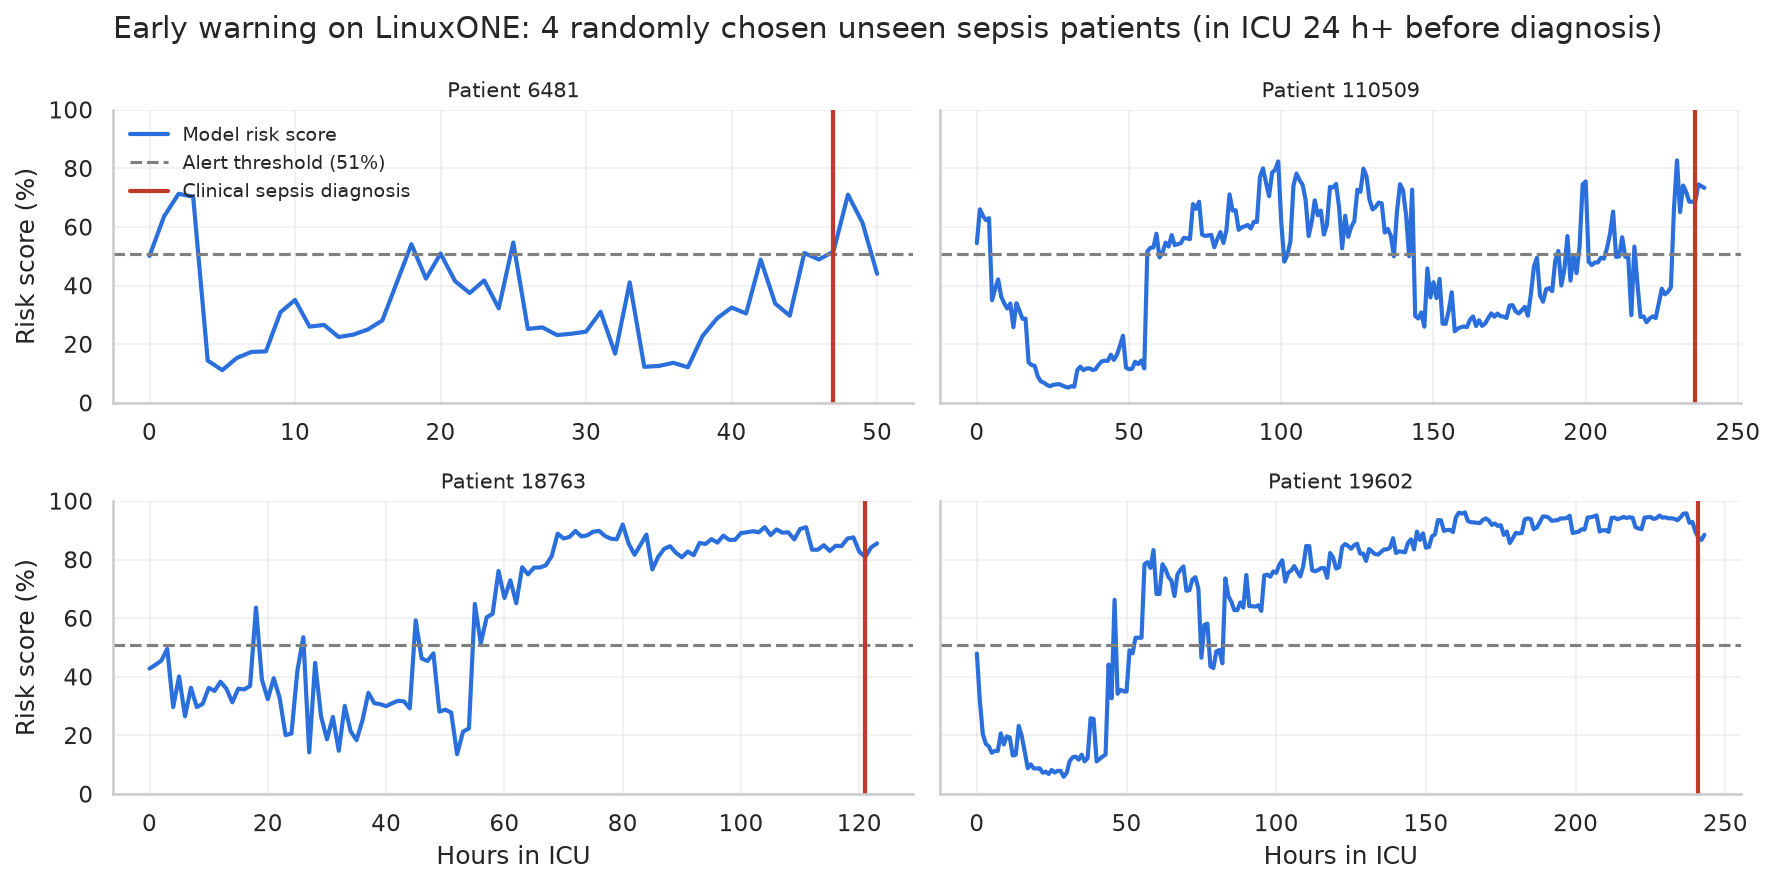

In [14]:
import matplotlib.pyplot as plt

test_prob = lgb_model.predict(X_full.iloc[test_idx][tier1_cols])
t = pd.DataFrame({'pid': groups[test_idx], 'hour': df['Hour'].values[test_idx],
                  'y': y.values[test_idx], 'p': test_prob})
thr = res1['thr']


rows = []
for pid, g in t[t.pid.isin(t.loc[t.y == 1, 'pid'].unique())].groupby('pid'):
    onset = g.loc[g.y == 1, 'hour'].min() + 6
    w12 = g[(g.hour > onset - 12) & (g.hour <= onset)]
    w6 = g[(g.hour > onset - 12) & (g.hour <= onset - 6)]
    rows.append((pid, onset, (w12.p >= thr).any(), (w6.p >= thr).any()))
lead = pd.DataFrame(rows, columns=['pid', 'onset', 'alert_12h', 'alert_6h_early'])


non = t[~t.pid.isin(lead.pid)]

rng = np.random.RandomState(0)
def random_window_alert(g):
    end = rng.randint(g.hour.min(), g.hour.max() + 1)
    return (g[(g.hour > end - 12) & (g.hour <= end)].p >= thr).any()
non_alert = non.groupby('pid').apply(random_window_alert)

print(f"Sepsis patients in test set: {len(lead):,}")
print(f"Sepsis patients alerted in the 12 h before diagnosis : {lead.alert_12h.mean()*100:.1f}%")
print(f"  ...of which alerted 6-12 h before diagnosis        : {lead.alert_6h_early.mean()*100:.1f}%")
print(f"Non-sepsis patients alerted in a 12 h window (false) : {non_alert.mean()*100:.1f}%")


eligible = lead[lead.onset >= 24].pid.values
pids = np.random.RandomState(1).choice(eligible, 4, replace=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharey=True)
for ax, pid in zip(axes.flat, pids):
    g = t[t.pid == pid]
    onset = lead.loc[lead.pid == pid, 'onset'].iloc[0]
    ax.plot(g.hour, g.p * 100, color='#2a6fdb', lw=2, label='Model risk score')
    ax.axhline(thr * 100, color='grey', ls='--', lw=1.5, label=f'Alert threshold ({thr*100:.0f}%)')
    ax.axvline(onset, color='#c0392b', lw=2, label='Clinical sepsis diagnosis')
    ax.set_title(f'Patient {pid}', fontsize=10); ax.set_ylim(0, 100)
    ax.grid(alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
for ax in axes[1]: ax.set_xlabel('Hours in ICU')
for ax in axes[:, 0]: ax.set_ylabel('Risk score (%)')
axes[0, 0].legend(frameon=False, loc='upper left', fontsize=9)
fig.suptitle('Early warning on LinuxONE: 4 randomly chosen unseen sepsis patients (in ICU 24 h+ before diagnosis)')
plt.tight_layout(); plt.savefig('chart_early_warning.png', dpi=200); plt.show()

In PhysioNet data `SepsisLabel` turns 1 six hours before clinical diagnosis, so the diagnosis time is the first positive hour + 6. For each sepsis patient we ask whether the model alerted during the 12 hours up to diagnosis (and, more strictly, 6 to 12 hours before). Non-sepsis patients are checked in a random 12-hour window to give a like-for-like false-alert rate.

72% of sepsis patients are flagged within 12 h of diagnosis and 59% 6 to 12 h earlier, against about 20% of non-sepsis patients flagged in a random window. This is the clearest evidence of useful lead time. The four example patients are chosen by a fixed rule and seed, so they are representative rather than cherry-picked.

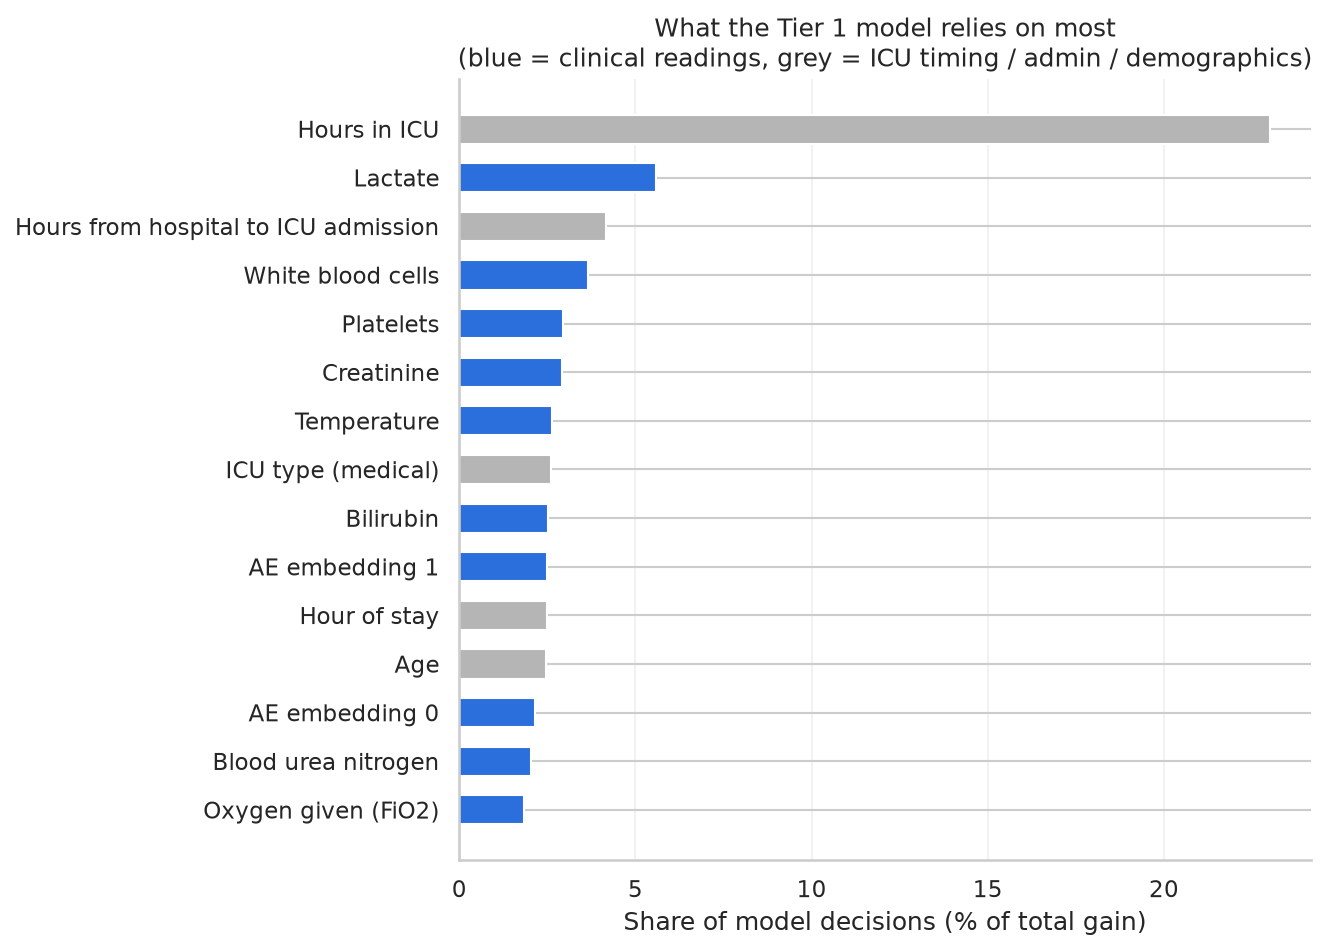

In [15]:
imp = pd.Series(lgb_model.feature_importance('gain'), index=tier1_cols)
imp = (imp / imp.sum() * 100).sort_values().tail(15)
names = {'ICULOS': 'Hours in ICU', 'HospAdmTime': 'Hours from hospital to ICU admission',
         'Hour': 'Hour of stay', 'Unit1': 'ICU type (medical)', 'Unit2': 'ICU type (surgical)',
         'Resp': 'Breathing rate', 'HR': 'Heart rate', 'Temp': 'Temperature', 'WBC': 'White blood cells',
         'BUN': 'Blood urea nitrogen', 'MAP': 'Mean arterial pressure', 'SBP': 'Systolic BP',
         'DBP': 'Diastolic BP', 'O2Sat': 'Oxygen saturation', 'FiO2': 'Oxygen given (FiO2)',
         'Bilirubin_total': 'Bilirubin', 'Bilirubin_direct': 'Bilirubin (direct)'}
admin = {'ICULOS', 'HospAdmTime', 'Hour', 'Unit1', 'Unit2', 'Age', 'Gender'}
labels = [names.get(c, c.replace('embed_', 'AE embedding ')) for c in imp.index]
colors = ['#b5b5b5' if c in admin else '#2a6fdb' for c in imp.index]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(labels, imp.values, color=colors, height=0.6)
ax.set_xlabel('Share of model decisions (% of total gain)')
ax.set_title('What the Tier 1 model relies on most\n(blue = clinical readings, grey = ICU timing / admin / demographics)')
ax.grid(axis='x', alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('chart_feature_importance.png', dpi=200); plt.show()

Importance is measured by total gain. Grey bars are timing, admin and demographic fields (`ICULOS`, `HospAdmTime`, `Hour`, ICU unit, Age, Gender); blue bars are clinical readings.

Timing variables are legitimate predictors (risk grows with length of stay), but they are not physiological evidence, and a high share for them means part of the score reflects *when* in the stay a patient is rather than *how sick* they look. This is worth checking by retraining without them. Gain importance also tells us what the trees split on, not causal effect.

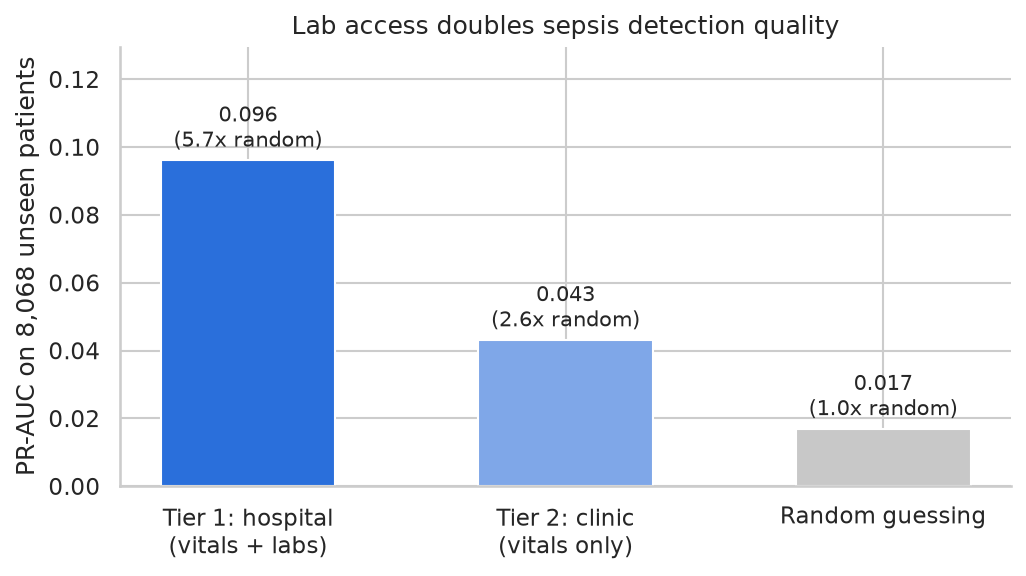

In [16]:
# ==== CHART 3: HOSPITAL (WITH LABS) vs CLINIC (VITALS ONLY) vs RANDOM ====
base = y.iloc[test_idx].mean()
vals = [res1['pr_auc'], res2['pr_auc'], base]
labels = ['Tier 1: hospital\n(vitals + labs)', 'Tier 2: clinic\n(vitals only)', 'Random guessing']

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, vals, color=['#2a6fdb', '#7fa7e8', '#c8c8c8'], width=0.55)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f'{v:.3f}\n({v / base:.1f}x random)',
            ha='center', va='bottom', fontsize=10)
ax.set_ylabel('PR-AUC on 8,068 unseen patients'); ax.set_ylim(0, max(vals) * 1.35)
ax.set_title('Lab access doubles sepsis detection quality')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('chart_tiers.png', dpi=200); plt.show()

Tier 1 reaches roughly 2.2x the PR-AUC of Tier 2 (0.096 vs 0.043) on the same unseen patients, and both are above the random baseline. The takeaway for deployment: labs materially improve detection, so a two-tier rollout (full model in hospitals, vitals-only screening in clinics) is sensible, with the clinic model expected to produce more false alarms per true catch.